<a href="https://colab.research.google.com/github/emmagolliard/projet-NN/blob/main/notebooks/projet_nn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Ce projet porte sur la reconnaissance des écuries de Formule 1 à partir de photographies de monoplaces. Nous avons d'abord préparé les images, puis entraîné un réseau convolutionnel construit de zéro et un modèle MobileNetV2 préentraîné. Nous avons ensuite adapté certaines couches de MobileNetV2, étudié l'effet des couleurs sur ses prédictions et vérifié la présence de photos similaires dans les différents ensembles de données.


In [ ]:
%pip install -q roboflow

In [ ]:
from roboflow import Roboflow
from getpass import getpass

api_key = getpass("Clé API Roboflow : ")
rf = Roboflow(api_key=api_key)
project = rf.workspace("yoav-fogel-yia3f").project("f1-car-recognition")
version = project.version(11)
dataset = version.download("yolov8")

print("Téléchargement terminé.")
print("Dossier :", dataset.location)


Clé API Roboflow : ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to F1-Car-Recognition-11 in yolov8:: 100%|██████████| 10250/10250 [00:01<00:00, 6746.64it/s]

Téléchargement terminé.
Dossier : /content/F1-Car-Recognition-11


Les images proviennent du dataset F1 Car Recognition disponible sur Roboflow, en version 11. Ce jeu de données a été conçu pour la détection d'objets : chaque annotation précise la position d'une voiture et le nom de son écurie. L'export contient 4 471 photographies pour l'entraînement, 432 pour la validation et 216 pour le test. Nous avons utilisé les annotations pour préparer un problème de classification d'images.


In [ ]:
import os

dataset_path = dataset.location

print("Contenu du dataset :")
print(os.listdir(dataset_path))

print("\nNombre d'images :")

for split in ["train", "valid", "test"]:
    path = os.path.join(dataset_path, split, "images")

    if os.path.exists(path):
        print(split, ":", len(os.listdir(path)))

Contenu du dataset :
['README.dataset.txt', 'train', 'test', 'README.roboflow.txt', 'valid', 'data.yaml']

Nombre d'images :
train : 4471
valid : 432
test : 216


In [ ]:
import yaml
from collections import Counter
from pathlib import Path

dataset_path = Path(dataset.location)


with open(dataset_path / "data.yaml", "r") as f:
    config = yaml.safe_load(f)

names = config["names"]

if isinstance(names, list):
    class_names = dict(enumerate(names))
else:
    class_names = {int(k): v for k, v in names.items()}

print("Nombre d'écuries :", len(class_names))

for class_id, team in class_names.items():
    print(class_id, ":", team)


for split in ["train", "valid", "test"]:
    counts = Counter()
    labels_path = dataset_path / split / "labels"

    for label_file in labels_path.glob("*.txt"):
        for line in label_file.read_text().splitlines():
            values = line.split()
            if values:
                counts[int(values[0])] += 1

    print(f"\n--- {split.upper()} ---")

    for class_id, team in class_names.items():
        print(f"{team} : {counts[class_id]} voitures")

Nombre d'écuries : 10
0 : Alfa-Romeo
1 : Alpha-Tauri
2 : Alpine
3 : Aston-Martin
4 : Ferrari
5 : Haas
6 : Mclaren
7 : Mercedes
8 : Red-Bull-Racing
9 : Williams

--- TRAIN ---
Alfa-Romeo : 783 voitures
Alpha-Tauri : 702 voitures
Alpine : 741 voitures
Aston-Martin : 1468 voitures
Ferrari : 1287 voitures
Haas : 885 voitures
Mclaren : 905 voitures
Mercedes : 1264 voitures
Red-Bull-Racing : 1304 voitures
Williams : 654 voitures

--- VALID ---
Alfa-Romeo : 75 voitures
Alpha-Tauri : 74 voitures
Alpine : 77 voitures
Aston-Martin : 138 voitures
Ferrari : 102 voitures
Haas : 61 voitures
Mclaren : 85 voitures
Mercedes : 122 voitures
Red-Bull-Racing : 99 voitures
Williams : 59 voitures

--- TEST ---
Alfa-Romeo : 34 voitures
Alpha-Tauri : 35 voitures
Alpine : 36 voitures
Aston-Martin : 69 voitures
Ferrari : 58 voitures
Haas : 36 voitures
Mclaren : 49 voitures
Mercedes : 58 voitures
Red-Bull-Racing : 57 voitures
Williams : 29 voitures


Le dataset comprend dix écuries, mais elles ne sont pas représentées en proportions égales. Par exemple, l'entraînement contient 1 468 annotations pour Aston Martin contre 654 pour Williams. Nous avons utilisé les coordonnées des boîtes YOLO pour découper les voitures et enregistrer chaque découpage dans le dossier correspondant à son écurie. Une photographie peut produire plusieurs découpages si plusieurs voitures y sont annotées.


In [ ]:
from PIL import Image
from collections import Counter

output_path = Path("/content/F1_Classification")
counts = Counter()

for split in ["train", "valid", "test"]:

    image_folder = dataset_path / split / "images"
    label_folder = dataset_path / split / "labels"

    for image_path in image_folder.iterdir():

        if image_path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue

        label_path = label_folder / (image_path.stem + ".txt")

        if not label_path.exists():
            continue

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        img_w, img_h = image.size

        annotations = label_path.read_text().splitlines()

        for i, annotation in enumerate(annotations):
            values = annotation.split()

            if len(values) != 5:
                continue

            class_id = int(values[0])

            if class_id not in class_names:
                continue

            xc, yc, w, h = map(float, values[1:])


            x1 = max(0, int((xc - w / 2) * img_w))
            y1 = max(0, int((yc - h / 2) * img_h))
            x2 = min(img_w, int((xc + w / 2) * img_w))
            y2 = min(img_h, int((yc + h / 2) * img_h))

            if x2 <= x1 or y2 <= y1:
                continue


            cropped_image = image.crop((x1, y1, x2, y2))


            team = class_names[class_id]
            team_folder = output_path / split / team
            team_folder.mkdir(parents=True, exist_ok=True)


            new_name = f"{image_path.stem}_{i}.jpg"
            cropped_image.save(team_folder / new_name)

            counts[(split, team)] += 1

print("Découpage terminé !")

for split in ["train", "valid", "test"]:
    print(f"\n{split.upper()} :")

    for team in class_names.values():
        print(f"{team} : {counts[(split, team)]} images")

Découpage terminé !

TRAIN :
Alfa-Romeo : 783 images
Alpha-Tauri : 702 images
Alpine : 741 images
Aston-Martin : 1468 images
Ferrari : 1287 images
Haas : 885 images
Mclaren : 905 images
Mercedes : 1264 images
Red-Bull-Racing : 1304 images
Williams : 654 images

VALID :
Alfa-Romeo : 75 images
Alpha-Tauri : 74 images
Alpine : 77 images
Aston-Martin : 138 images
Ferrari : 102 images
Haas : 61 images
Mclaren : 85 images
Mercedes : 122 images
Red-Bull-Racing : 99 images
Williams : 59 images

TEST :
Alfa-Romeo : 34 images
Alpha-Tauri : 35 images
Alpine : 36 images
Aston-Martin : 69 images
Ferrari : 58 images
Haas : 36 images
Mclaren : 49 images
Mercedes : 58 images
Red-Bull-Racing : 57 images
Williams : 29 images


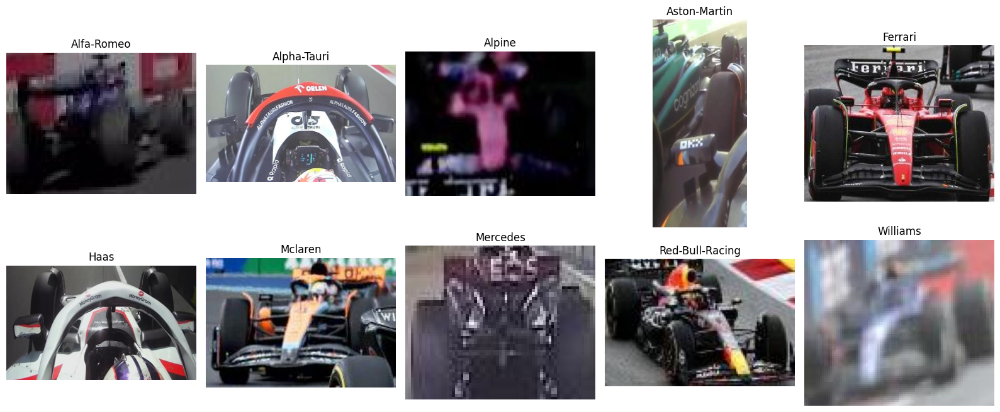

In [ ]:
import matplotlib.pyplot as plt
import random

random.seed(42)

train_path = output_path / "train"

plt.figure(figsize=(16, 7))

for i, team in enumerate(class_names.values()):

    images = list((train_path / team).glob("*.jpg"))

    if not images:
        continue

    image_path = random.choice(images)

    plt.subplot(2, 5, i + 1)
    plt.imshow(Image.open(image_path))
    plt.title(team)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from google.colab import drive
from pathlib import Path
import shutil

output_path = Path("/content/F1_Classification")
zip_drive = Path("/content/drive/MyDrive/F1_Classification.zip")

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

if not (output_path / "train").exists():
    if not zip_drive.exists():
        raise FileNotFoundError("Archive F1_Classification.zip introuvable dans Google Drive.")
    shutil.unpack_archive(str(zip_drive), "/content")

print("Dataset restauré :", (output_path / "train").exists())


Mounted at /content/drive
Dataset restauré : True


Après le découpage, nous disposons de 9 993 images de voitures pour l'entraînement, 892 pour la validation et 461 pour le test. Les images sont redimensionnées en 160 × 160 pixels et chargées par lots de 32. Il s'agit de découpages issus des photographies de départ, et non forcément d'autant de prises de vue indépendantes. Nous conservons les trois ensembles séparés pour entraîner les modèles, suivre leur progression et mesurer leurs performances.


In [ ]:
import tensorflow as tf

IMG_SIZE = (160, 160)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    output_path / "train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    output_path / "valid",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    output_path / "test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)


team_names = train_ds.class_names

print("\nÉcuries :", team_names)
print("Nombre de classes :", len(team_names))


AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

Found 9993 files belonging to 10 classes.
Found 892 files belonging to 10 classes.
Found 461 files belonging to 10 classes.

Écuries : ['Alfa-Romeo', 'Alpha-Tauri', 'Alpine', 'Aston-Martin', 'Ferrari', 'Haas', 'Mclaren', 'Mercedes', 'Red-Bull-Racing', 'Williams']
Nombre de classes : 10


Nous avons commencé par un réseau convolutionnel composé de trois couches Conv2D, chacune suivie d'un MaxPooling, puis d'une couche dense et d'une sortie softmax à dix classes. Les convolutions extraient progressivement des motifs visuels, comme les contours et les éléments de carrosserie. Le pooling réduit la taille des représentations, tandis que le dropout désactive aléatoirement une partie des neurones pendant l'entraînement pour limiter le surapprentissage. Le modèle compte 102 154 paramètres entraînables.


In [ ]:
from tensorflow.keras import layers, models

num_classes = len(team_names)

cnn_model = models.Sequential([
    layers.Input(shape=(160, 160, 3)),


    layers.Rescaling(1./255),


    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),


    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation="softmax")
])

cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 158, 158, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 79, 79, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 77, 77, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 38, 38, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 36, 36, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,154 (399.04 KB)

 Trainable params: 102,154 (399.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_cnn = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stop]
)

Epoch 1/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 35s 73ms/step - accuracy: 0.2658 - loss: 2.0065 - val_accuracy: 0.4193 - val_loss: 1.6930
Epoch 2/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 16s 27ms/step - accuracy: 0.4371 - loss: 1.5645 - val_accuracy: 0.5392 - val_loss: 1.3966
Epoch 3/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.5354 - loss: 1.3593 - val_accuracy: 0.6211 - val_loss: 1.1906
Epoch 4/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.5741 - loss: 1.2342 - val_accuracy: 0.6480 - val_loss: 1.1042
Epoch 5/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.6179 - loss: 1.1306 - val_accuracy: 0.7096 - val_loss: 0.9495
Epoch 6/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 32ms/step - accuracy: 0.6564 - loss: 1.0306 - val_accuracy: 0.7242 - val_loss: 0.8953
Epoch 7/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.6812 - loss: 0.9730 - val_accuracy: 0.7197 - val_loss: 0.8413
Epoch 8/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - accuracy: 0.6905 - loss: 0.9121 - va

Le CNN a été entraîné pendant 20 époques, avec un arrêt anticipé prévu si la perte de validation cessait de s'améliorer. Il a effectué les 20 époques. À la dernière, l'accuracy d'entraînement atteint 79,92 % et celle de validation 81,50 %, avec une perte de validation de 0,5528. Les courbes montrent une hausse progressive de l'accuracy et une baisse globale de la perte. Il n'y a pas de remontée durable de la perte de validation sur cette exécution, même si les valeurs fluctuent d'une époque à l'autre.


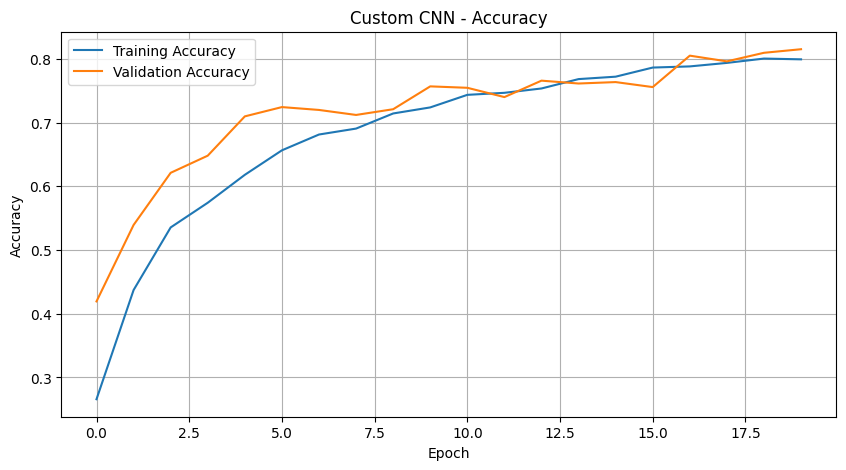

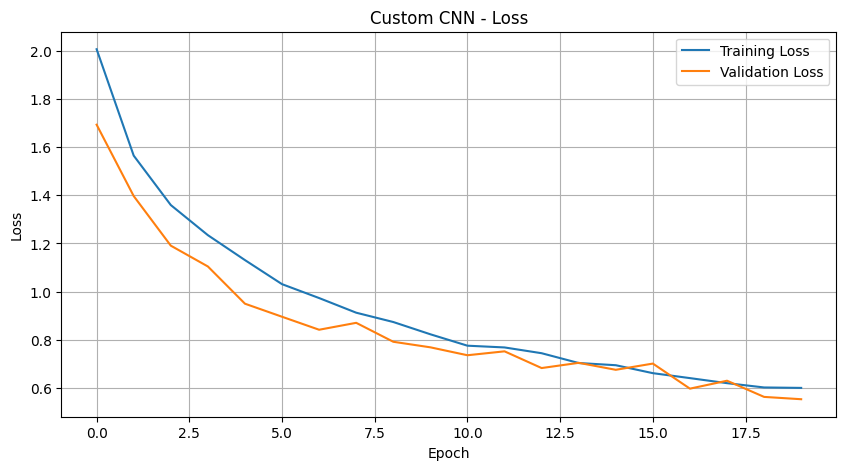

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_cnn.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_cnn.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Custom CNN - Accuracy")
plt.legend()
plt.grid()
plt.show()


plt.figure(figsize=(10, 5))

plt.plot(
    history_cnn.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_cnn.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Custom CNN - Loss")
plt.legend()
plt.grid()
plt.show()

Pour la deuxième approche, nous avons utilisé MobileNetV2, préentraîné sur ImageNet. Ses couches convolutionnelles ont d'abord été gelées pour conserver les caractéristiques déjà apprises, puis nous avons ajouté une couche de sortie adaptée aux dix écuries. Sur les 2 270 794 paramètres du modèle complet, seuls les 12 810 paramètres de cette nouvelle couche sont entraînables à cette étape. Les images sont préparées avec la fonction de prétraitement propre à MobileNetV2.


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model


base_model = tf.keras.applications.MobileNetV2(
    input_shape=(160, 160, 3),
    include_top=False,
    weights="imagenet"
)


base_model.trainable = False


inputs = tf.keras.Input(shape=(160, 160, 3))


x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)


x = base_model(x, training=False)


x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    num_classes,
    activation="softmax"
)(x)

mobilenet_model = Model(inputs, outputs)

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
import tensorflow as tf
early_stop_tl = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_mobilenet = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stop_tl]
)

Epoch 1/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 67s 140ms/step - accuracy: 0.5402 - loss: 1.4055 - val_accuracy: 0.7433 - val_loss: 0.8380
Epoch 2/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step - accuracy: 0.7533 - loss: 0.7704 - val_accuracy: 0.7948 - val_loss: 0.6835
Epoch 3/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - accuracy: 0.7983 - loss: 0.6311 - val_accuracy: 0.8139 - val_loss: 0.6360
Epoch 4/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.8206 - loss: 0.5630 - val_accuracy: 0.8083 - val_loss: 0.6358
Epoch 5/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 28ms/step - accuracy: 0.8312 - loss: 0.5179 - val_accuracy: 0.8173 - val_loss: 0.6067
Epoch 6/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - accuracy: 0.8443 - loss: 0.4793 - val_accuracy: 0.8061 - val_loss: 0.5732
Epoch 7/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 23ms/step - accuracy: 0.8548 - loss: 0.4552 - val_accuracy: 0.8229 - val_loss: 0.5688
Epoch 8/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - accuracy: 0.8557 - loss: 0.4346 - val_

Le graphique compare les accuracies de validation des deux approches. Le CNN progresse assez régulièrement sur ses 20 époques. MobileNetV2 part avec une accuracy plus élevée grâce aux caractéristiques apprises sur ImageNet, mais sa courbe varie au cours de l'entraînement. Sa meilleure perte de validation est obtenue à l'époque 14, où l'accuracy vaut 83,18 %. Pour départager les modèles, il faut également les évaluer sur le même ensemble de test.


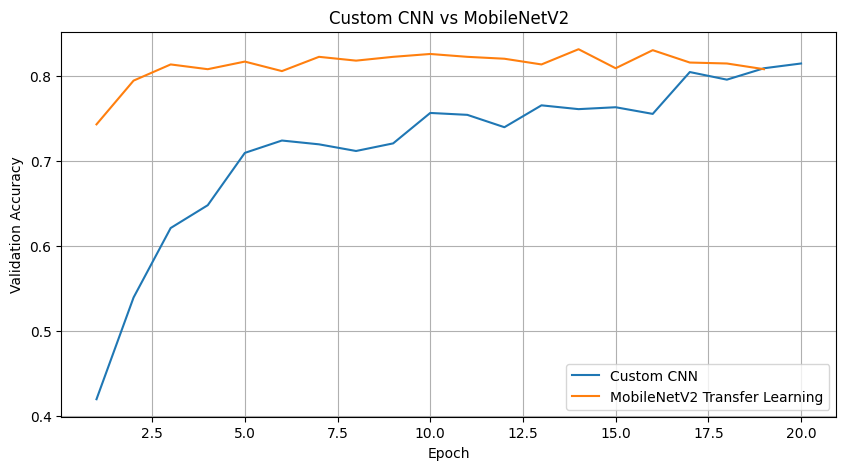

In [ ]:
import matplotlib.pyplot as plt

epochs_cnn = range(1, len(history_cnn.history["val_accuracy"]) + 1)
epochs_tl = range(1, len(history_mobilenet.history["val_accuracy"]) + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs_cnn,
    history_cnn.history["val_accuracy"],
    label="Custom CNN"
)

plt.plot(
    epochs_tl,
    history_mobilenet.history["val_accuracy"],
    label="MobileNetV2 Transfer Learning"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Custom CNN vs MobileNetV2")
plt.legend()
plt.grid()
plt.show()

In [ ]:
from pathlib import Path

models_path = Path("/content/drive/MyDrive/F1_Models")
models_path.mkdir(parents=True, exist_ok=True)

cnn_model.save(models_path / "cnn_f1.keras")
mobilenet_model.save(models_path / "mobilenet_f1.keras")

print("Les deux modèles sont sauvegardés !")

Les deux modèles sont sauvegardés !


Pour MobileNetV2, nous avons prévu un maximum de 20 époques et un arrêt anticipé après cinq époques sans amélioration de la perte de validation. L'entraînement s'est arrêté après 19 époques. La perte de validation minimale, 0,5504, a été obtenue à l'époque 14, avec une accuracy de 83,18 %. Grâce à l'option de restauration des meilleurs poids, le modèle revient à l'état de cette époque plutôt que de conserver les poids de la dernière.


In [ ]:

cnn_loss, cnn_accuracy = cnn_model.evaluate(
    test_ds,
    verbose=0
)


mobilenet_loss, mobilenet_accuracy = mobilenet_model.evaluate(
    test_ds,
    verbose=0
)

print("=== CUSTOM CNN ===")
print(f"Test Accuracy : {cnn_accuracy:.4f}")
print(f"Test Loss : {cnn_loss:.4f}")

print("\n=== MOBILENETV2 ===")
print(f"Test Accuracy : {mobilenet_accuracy:.4f}")
print(f"Test Loss : {mobilenet_loss:.4f}")

=== CUSTOM CNN ===
Test Accuracy : 0.8200
Test Loss : 0.5485

=== MOBILENETV2 ===
Test Accuracy : 0.8091
Test Loss : 0.6497


L'évaluation sur les 461 images de test donne une accuracy de 82,00 % et une perte de 0,5485 pour le CNN personnalisé. MobileNetV2, avec ses couches préentraînées encore gelées, obtient 80,91 % et une perte de 0,6497. Le CNN fait donc légèrement mieux dans cette première comparaison, malgré le préentraînement de MobileNetV2. L'écart est limité et ne permet pas de conclure qu'une architecture est toujours supérieure à l'autre.


Pour comprendre les erreurs au-delà de l'accuracy globale, nous avons calculé une matrice de confusion et un rapport de classification pour chaque modèle. Les nombres sur la diagonale de la matrice correspondent aux voitures correctement classées. Les autres cases permettent de voir quelles écuries sont confondues. La précision, le rappel et le score F1 donnent aussi une vue plus détaillée des résultats par équipe.


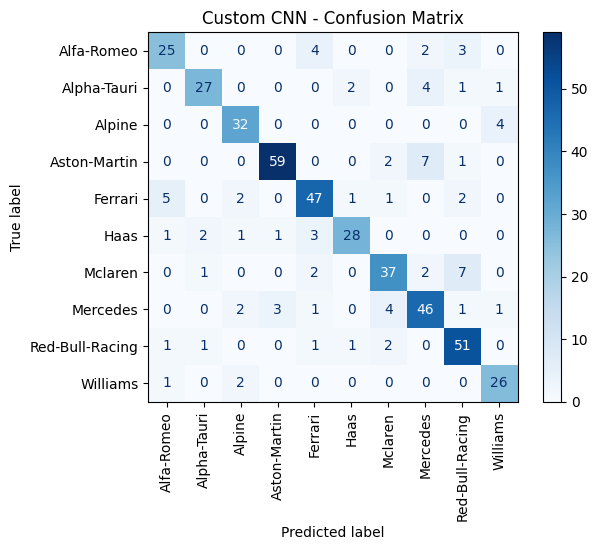

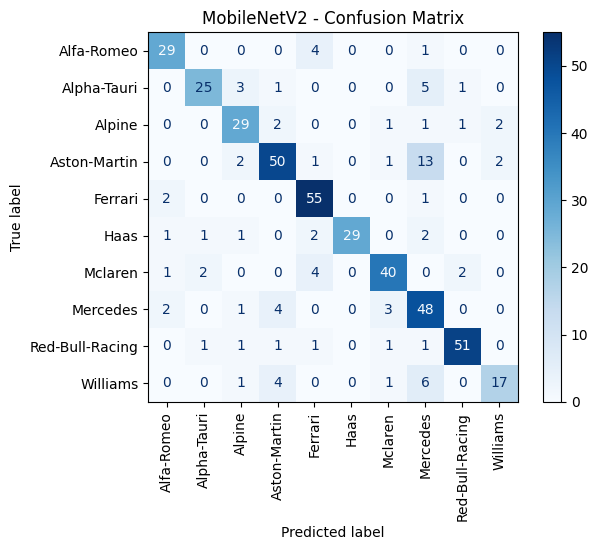

=== CUSTOM CNN ===
                 precision    recall  f1-score   support

     Alfa-Romeo       0.76      0.74      0.75        34
    Alpha-Tauri       0.87      0.77      0.82        35
         Alpine       0.82      0.89      0.85        36
   Aston-Martin       0.94      0.86      0.89        69
        Ferrari       0.81      0.81      0.81        58
           Haas       0.88      0.78      0.82        36
        Mclaren       0.80      0.76      0.78        49
       Mercedes       0.75      0.79      0.77        58
Red-Bull-Racing       0.77      0.89      0.83        57
       Williams       0.81      0.90      0.85        29

       accuracy                           0.82       461
      macro avg       0.82      0.82      0.82       461
   weighted avg       0.82      0.82      0.82       461

=== MOBILENETV2 ===
                 precision    recall  f1-score   support

     Alfa-Romeo       0.83      0.85      0.84        34
    Alpha-Tauri       0.86      0.71      0.7

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)


y_true = np.concatenate([
    labels.numpy()
    for images, labels in test_ds
])


cnn_predictions = cnn_model.predict(test_ds, verbose=0)
mobilenet_predictions = mobilenet_model.predict(test_ds, verbose=0)

y_pred_cnn = np.argmax(cnn_predictions, axis=1)
y_pred_mobilenet = np.argmax(mobilenet_predictions, axis=1)


cm_cnn = confusion_matrix(y_true, y_pred_cnn)

ConfusionMatrixDisplay(
    confusion_matrix=cm_cnn,
    display_labels=team_names
).plot(xticks_rotation=90, cmap="Blues")

plt.title("Custom CNN - Confusion Matrix")
plt.show()


cm_mobilenet = confusion_matrix(y_true, y_pred_mobilenet)

ConfusionMatrixDisplay(
    confusion_matrix=cm_mobilenet,
    display_labels=team_names
).plot(xticks_rotation=90, cmap="Blues")

plt.title("MobileNetV2 - Confusion Matrix")
plt.show()


print("=== CUSTOM CNN ===")
print(classification_report(
    y_true,
    y_pred_cnn,
    target_names=team_names,
    zero_division=0
))

print("=== MOBILENETV2 ===")
print(classification_report(
    y_true,
    y_pred_mobilenet,
    target_names=team_names,
    zero_division=0
))

Les deux modèles ont des performances assez proches, mais pas les mêmes difficultés selon les écuries. Le CNN reconnaît 86 % des Aston Martin, 89 % des Red Bull Racing et 90 % des Williams. MobileNetV2 reconnaît 55 Ferrari sur 58, soit environ 95 %, mais seulement 17 Williams sur 29. Il classe également 13 Aston Martin et 6 Williams comme des Mercedes. Ces confusions pourraient venir de caractéristiques visuelles proches, mais il faudrait examiner les images concernées pour en connaître la raison. Le score F1 macro est d'environ 0,82 pour le CNN et 0,81 pour MobileNetV2.


Nous avons ensuite essayé d'adapter davantage MobileNetV2 aux photographies de Formule 1. Au lieu de garder toutes les couches préentraînées gelées, nous avons autorisé l'apprentissage dans une partie des dernières couches. Le but est de conserver les caractéristiques générales du modèle tout en améliorant sa capacité à distinguer les écuries.


In [ ]:
import tensorflow as tf


base_model.trainable = True


for layer in base_model.layers[:-30]:
    layer.trainable = False


for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False


mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Nombre de couches :", len(base_model.layers))
print("Couches entraînables :", sum(layer.trainable for layer in base_model.layers))

Nombre de couches : 154
Couches entraînables : 19


In [ ]:
early_stop_ft = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_finetuning = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stop_ft]
)

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 41s 86ms/step - accuracy: 0.8901 - loss: 0.3232 - val_accuracy: 0.8408 - val_loss: 0.4814
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.9231 - loss: 0.2257 - val_accuracy: 0.8487 - val_loss: 0.4744
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.9427 - loss: 0.1758 - val_accuracy: 0.8610 - val_loss: 0.4573
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 32ms/step - accuracy: 0.9577 - loss: 0.1351 - val_accuracy: 0.8610 - val_loss: 0.4318
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.9671 - loss: 0.1084 - val_accuracy: 0.8655 - val_loss: 0.4409
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 25ms/step - accuracy: 0.9760 - loss: 0.0842 - val_accuracy: 0.8688 - val_loss: 0.4414
Epoch 7/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 40ms/step - accuracy: 0.9783 - loss: 0.0754 - val_accuracy: 0.8610 - val_loss: 0.4396


Pendant le fine-tuning, l'accuracy d'entraînement continue de progresser, mais les valeurs de validation évoluent moins régulièrement. La perte de validation atteint son minimum à l'époque 4, puis reste un peu plus élevée. L'arrêt anticipé permet de retrouver les poids de cette quatrième époque. Les meilleures valeurs d'entraînement ne correspondent donc pas nécessairement au modèle qui généralise le mieux.


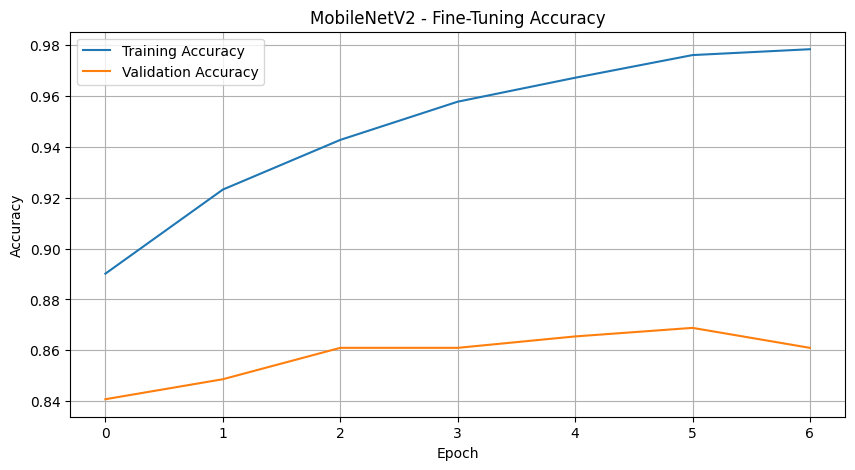

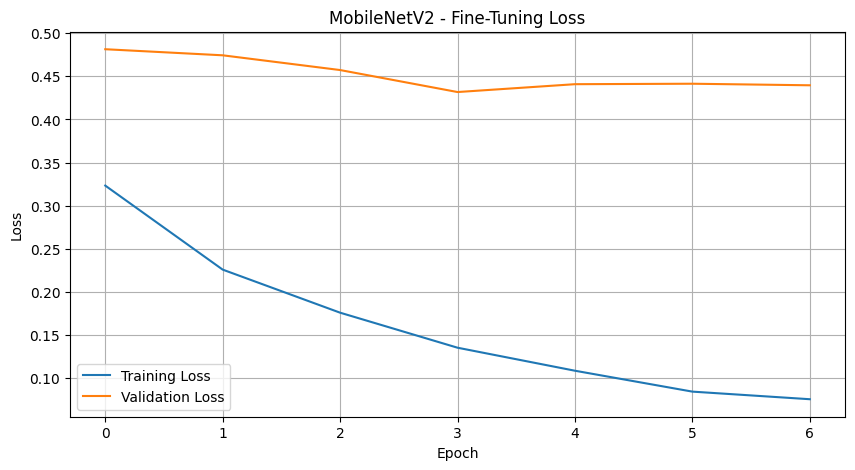

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    history_finetuning.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_finetuning.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MobileNetV2 - Fine-Tuning Accuracy")
plt.legend()
plt.grid()
plt.show()


plt.figure(figsize=(10, 5))

plt.plot(
    history_finetuning.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_finetuning.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MobileNetV2 - Fine-Tuning Loss")
plt.legend()
plt.grid()
plt.show()

In [ ]:
best_ft_epoch = (
    history_finetuning.history["val_loss"].index(
        min(history_finetuning.history["val_loss"])
    ) + 1
)

print("Meilleure époque du fine-tuning :", best_ft_epoch)

print(
    "Meilleure validation loss :",
    min(history_finetuning.history["val_loss"])
)

print(
    "Validation accuracy à cette époque :",
    history_finetuning.history["val_accuracy"][best_ft_epoch - 1]
)

Meilleure époque du fine-tuning : 4
Meilleure validation loss : 0.43175777792930603
Validation accuracy à cette époque : 0.8609865307807922


Pour le fine-tuning, nous avons autorisé l'entraînement des dernières couches de MobileNetV2 en conservant les couches BatchNormalization gelées. Parmi les 30 dernières couches, 19 sont effectivement entraînables. Le taux d'apprentissage a été réduit à 0,00001 pour modifier les poids progressivement. Le meilleur résultat en validation est atteint à la quatrième époque, avec une perte de 0,4318 et une accuracy de 86,10 %. C'est mieux que la perte minimale de 0,5504 obtenue avant le fine-tuning.


Après avoir retenu les poids correspondant à la meilleure perte de validation, nous avons évalué le MobileNetV2 fine-tuné sur les mêmes 461 images de test que les deux premiers modèles.


In [ ]:

ft_loss, ft_accuracy = mobilenet_model.evaluate(
    test_ds,
    verbose=0
)

print("=== MOBILENETV2 FINE-TUNED ===")
print(f"Test Accuracy : {ft_accuracy:.4f}")
print(f"Test Loss : {ft_loss:.4f}")

=== MOBILENETV2 FINE-TUNED ===
Test Accuracy : 0.8416
Test Loss : 0.5869


Le MobileNetV2 fine-tuné obtient 84,16 % d'accuracy sur le test, avec une perte de 0,5869. Son accuracy dépasse celle du MobileNetV2 initial (80,91 %) et celle du CNN personnalisé (82,00 %). En revanche, le CNN conserve une perte de test légèrement plus faible, à 0,5485. Le fine-tuning améliore donc le nombre de bonnes prédictions dans cette exécution, mais pas toutes les métriques.


Nous avons ensuite cherché à mesurer l'importance de la couleur dans la reconnaissance des écuries. Les photographies du jeu de test ont été converties en niveaux de gris, puis ramenées à trois canaux pour rester compatibles avec MobileNetV2. Nous avons gardé exactement le même modèle fine-tuné : seuls les pixels des images ont changé.


In [ ]:
import tensorflow as tf


def convert_to_grayscale(images, labels):


    gray_images = tf.image.rgb_to_grayscale(images)


    gray_images = tf.image.grayscale_to_rgb(gray_images)

    return gray_images, labels

test_gray_ds = test_ds.map(
    convert_to_grayscale,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_gray_ds = test_gray_ds.prefetch(tf.data.AUTOTUNE)

print("Dataset en niveaux de gris créé !")

Dataset en niveaux de gris créé !


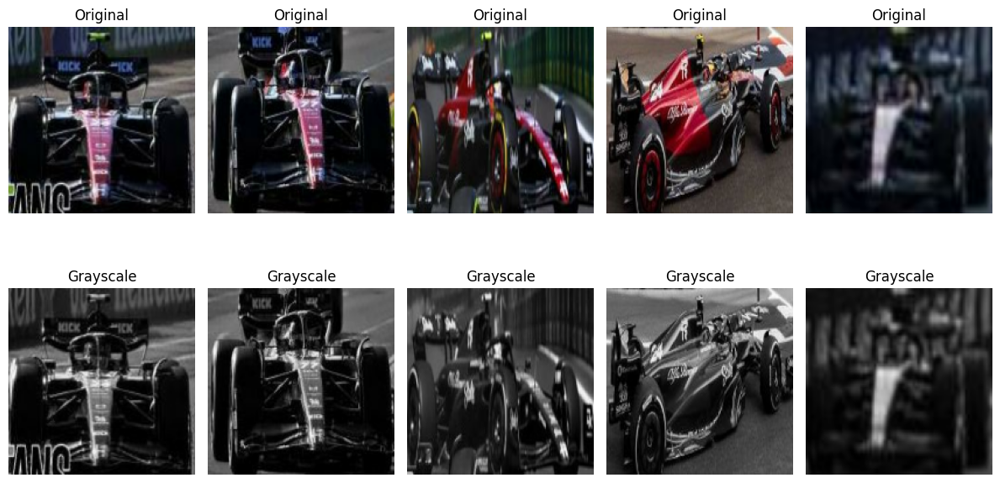

In [ ]:
import matplotlib.pyplot as plt

images, labels = next(iter(test_ds))
gray_images, _ = next(iter(test_gray_ds))

plt.figure(figsize=(12, 7))

for i in range(5):


    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title("Original")
    plt.axis("off")


    plt.subplot(2, 5, i + 6)
    plt.imshow(gray_images[i].numpy().astype("uint8"))
    plt.title("Grayscale")
    plt.axis("off")

plt.tight_layout()
plt.show()

Nous avons comparé les résultats du MobileNetV2 fine-tuné sur les images de test en couleur et sur leurs versions en niveaux de gris. Cette expérience mesure sa sensibilité à la disparition des couleurs. Elle ne permet toutefois pas de savoir précisément quels éléments de l'image le réseau utilise pour prendre sa décision.


In [ ]:

color_loss, color_accuracy = mobilenet_model.evaluate(
    test_ds,
    verbose=0
)


gray_loss, gray_accuracy = mobilenet_model.evaluate(
    test_gray_ds,
    verbose=0
)

print("=== MOBILE NET V2 FINE-TUNED ===")

print("\nImages en couleur :")
print(f"Accuracy : {color_accuracy:.4f}")
print(f"Loss : {color_loss:.4f}")

print("\nImages en niveaux de gris :")
print(f"Accuracy : {gray_accuracy:.4f}")
print(f"Loss : {gray_loss:.4f}")

print("\nDifférence d'accuracy :")
print(f"{(color_accuracy - gray_accuracy) * 100:.2f} points de pourcentage")

=== MOBILE NET V2 FINE-TUNED ===

Images en couleur :
Accuracy : 0.8416
Loss : 0.5869

Images en niveaux de gris :
Accuracy : 0.2820
Loss : 4.3338

Différence d'accuracy :
55.97 points de pourcentage


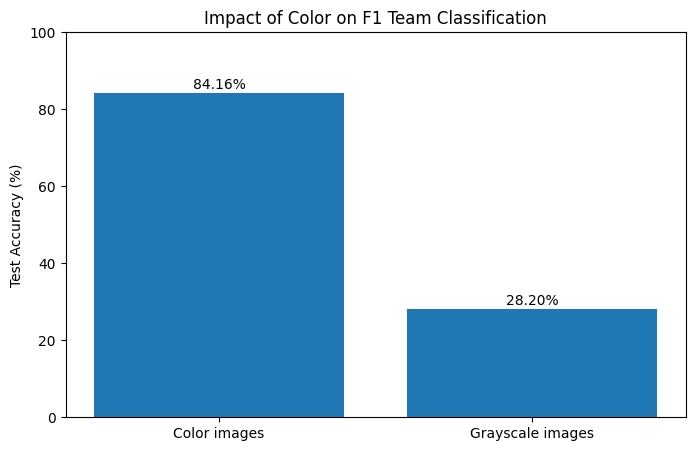

In [ ]:
import matplotlib.pyplot as plt

models = ["Color images", "Grayscale images"]
accuracies = [color_accuracy * 100, gray_accuracy * 100]

plt.figure(figsize=(8, 5))

bars = plt.bar(models, accuracies)

plt.ylabel("Test Accuracy (%)")
plt.title("Impact of Color on F1 Team Classification")
plt.ylim(0, 100)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{accuracy:.2f}%",
        ha="center"
    )

plt.show()

Sur les images couleur, le MobileNetV2 fine-tuné obtient 84,16 % d'accuracy, avec une perte de 0,5869. En niveaux de gris, l'accuracy descend à 28,20 % et la perte augmente à 4,3338. La baisse est de 55,97 points de pourcentage. Les couleurs semblent donc jouer un rôle important dans les prédictions, ce qui est cohérent avec les livrées distinctives des écuries. Il faut cependant garder à l'esprit que le modèle a été entraîné sur des images couleur : le passage au gris change aussi le type d'images qu'il reçoit.


À ce stade, le CNN obtient 82,00 % d'accuracy sur le test, MobileNetV2 sans fine-tuning 80,91 % et MobileNetV2 après fine-tuning 84,16 %. Nous avons aussi observé une forte baisse de performance sur les images en niveaux de gris. Avant de tirer une conclusion sur la généralisation des modèles, nous avons vérifié si des photographies identiques ou très similaires se retrouvaient dans plusieurs ensembles.


Pour contrôler le risque de retrouver des photographies presque identiques dans différents ensembles, nous avons comparé les empreintes des images avec un hachage perceptuel. Contrairement à une comparaison de fichiers octet par octet, cette méthode peut détecter des ressemblances malgré certaines modifications visuelles. Elle fournit cependant des paires à examiner et ne suffit pas à confirmer automatiquement tous les doublons.


In [ ]:
%pip install -q imagehash

from pathlib import Path
from PIL import Image
import imagehash
import hashlib
import numpy as np

data_path = Path("/content/F1_Classification")
splits = ["train", "valid", "test"]

records = {}

for split in splits:
    records[split] = []

    for path in sorted((data_path / split).glob("*/*")):
        if path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue

        with Image.open(path) as img:
            perceptual_hash = int(str(imagehash.phash(img)), 16)

        file_hash = hashlib.sha256(path.read_bytes()).hexdigest()

        records[split].append({
            "path": path,
            "phash": perceptual_hash,
            "sha256": file_hash
        })

    print(f"{split} : {len(records[split])} images analysées")

lookup = np.array(
    [int(i).bit_count() for i in range(256)],
    dtype=np.uint8
)

def compare_splits(split_a, split_b, threshold=5):
    a = records[split_a]
    b = records[split_b]

    hashes_a = np.array([r["phash"] for r in a], dtype=np.uint64)

    exact = []
    similar = []

    for item_b in b:
        hashes_xor = np.bitwise_xor(
            hashes_a,
            np.uint64(item_b["phash"])
        )

        bytes_array = hashes_xor.view(np.uint8).reshape(-1, 8)
        distances = lookup[bytes_array].sum(axis=1)

        for idx in np.where(distances <= threshold)[0]:
            item_a = a[idx]
            distance = int(distances[idx])

            pair = (item_a["path"], item_b["path"], distance)

            if item_a["sha256"] == item_b["sha256"]:
                exact.append(pair)
            else:
                similar.append(pair)

    print(f"\n{split_a} / {split_b}")
    print("Fichiers identiques :", len(exact))
    print("Images très similaires :", len(similar))

    return exact, similar

exact_tv, similar_tv = compare_splits("train", "valid")
exact_tt, similar_tt = compare_splits("train", "test")
exact_vt, similar_vt = compare_splits("valid", "test")

suspicious_pairs = (
    exact_tv + similar_tv +
    exact_tt + similar_tt +
    exact_vt + similar_vt
)

print("\nTotal de paires suspectes :", len(suspicious_pairs))

train : 9993 images analysées
valid : 892 images analysées
test : 461 images analysées

train / valid
Fichiers identiques : 0
Images très similaires : 54

train / test
Fichiers identiques : 0
Images très similaires : 64

valid / test
Fichiers identiques : 0
Images très similaires : 5

Total de paires suspectes : 123


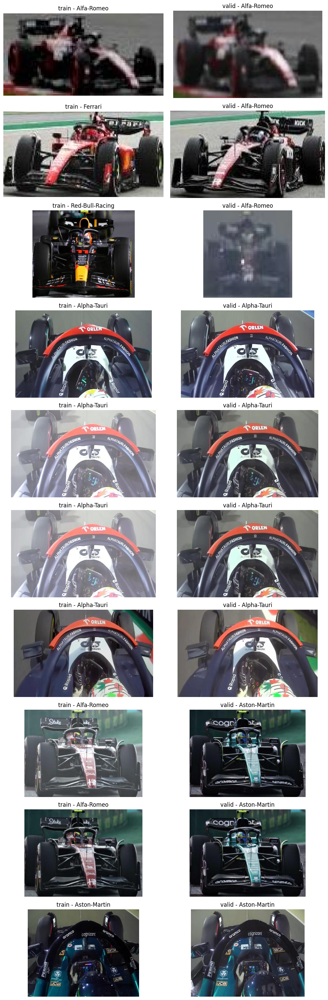

In [ ]:
import matplotlib.pyplot as plt

if len(suspicious_pairs) == 0:
    print("Aucune paire suspecte détectée avec ce seuil.")

else:
    pairs_to_show = suspicious_pairs[:10]

    fig, axes = plt.subplots(
        len(pairs_to_show), 2,
        figsize=(10, 3 * len(pairs_to_show)),
        squeeze=False
    )

    for i, (path1, path2, distance) in enumerate(pairs_to_show):

        with Image.open(path1) as img:
            axes[i, 0].imshow(img.convert("RGB"))

        with Image.open(path2) as img:
            axes[i, 1].imshow(img.convert("RGB"))

        axes[i, 0].set_title(
            f"{path1.parent.parent.name} - {path1.parent.name}"
        )

        axes[i, 1].set_title(
            f"{path2.parent.parent.name} - {path2.parent.name}"
        )

        for ax in axes[i]:
            ax.axis("off")

    plt.tight_layout()
    plt.show()

Nous avons affiché les paires les plus proches entre l'entraînement et le test, en commençant par celles dont la distance perceptuelle est la plus faible. Cette comparaison permet de vérifier si les images représentent réellement la même photographie ou seulement deux prises de vue ressemblantes.


Nombre de paires suspectes train/test : 64


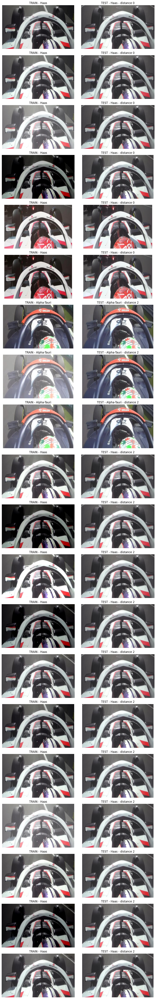

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

pairs = sorted(exact_tt + similar_tt, key=lambda x: x[2])

print("Nombre de paires suspectes train/test :", len(pairs))

n = min(20, len(pairs))

if n == 0:
    print("Aucune paire suspecte.")
else:
    fig, axes = plt.subplots(n, 2, figsize=(10, 3 * n), squeeze=False)

    for i, (train_path, test_path, distance) in enumerate(pairs[:n]):
        with Image.open(train_path) as img:
            axes[i, 0].imshow(img.convert("RGB"))

        with Image.open(test_path) as img:
            axes[i, 1].imshow(img.convert("RGB"))

        axes[i, 0].set_title(
            f"TRAIN - {train_path.parent.name}"
        )
        axes[i, 1].set_title(
            f"TEST - {test_path.parent.name} - distance {distance}"
        )

        for ax in axes[i]:
            ax.axis("off")

    plt.tight_layout()
    plt.show()

Plusieurs des images affichées correspondent à la même prise de vue avec de petites variations de luminosité ou de cadrage. Nous avons donc compté les images suspectes distinctes du jeu de test, car une seule image peut apparaître dans plusieurs paires de comparaison.


In [ ]:
from pathlib import Path

suspect_test = {
    str(test_path)
    for train_path, test_path, distance in exact_tt + similar_tt
}

suspect_test.update(
    str(test_path)
    for valid_path, test_path, distance in exact_vt + similar_vt
)

all_test_images = {
    str(path)
    for path in (data_path / "test").glob("*/*")
    if path.suffix.lower() in [".jpg", ".jpeg", ".png"]
}

clean_test = all_test_images - suspect_test

print("Images de test au total :", len(all_test_images))
print("Images suspectes distinctes :", len(suspect_test))
print("Images non signalées :", len(clean_test))

Images de test au total : 461
Images suspectes distinctes : 14
Images non signalées : 447


Nous avons constitué un ensemble de test filtré avec les images qui n'avaient pas été signalées comme similaires. Les fichiers originaux n'ont pas été supprimés. Les images ont simplement été rechargées avec les mêmes dimensions pour effectuer une évaluation complémentaire.


In [ ]:
import tensorflow as tf
from pathlib import Path

clean_test_paths = sorted(Path(p) for p in clean_test)

labels = []
image_paths = []

for path in clean_test_paths:
    image_paths.append(str(path))
    labels.append(team_names.index(path.parent.name))

clean_ds = tf.data.Dataset.from_tensor_slices(
    (image_paths, labels)
)

def load_clean_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, (160, 160))
    return image, label

clean_ds = clean_ds.map(
    load_clean_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

clean_ds = clean_ds.batch(32).prefetch(tf.data.AUTOTUNE)

print("Nombre d'images :", len(clean_test_paths))

Nombre d'images : 447


Nous réévaluons sur cet ensemble filtré le CNN personnalisé et la version fine-tunée de MobileNetV2. La version initiale de MobileNetV2 n'est pas réévaluée ici, car ses poids avant fine-tuning n'ont pas été conservés dans une variable distincte.


In [ ]:
models_to_compare = {
    "CNN personnalisé": cnn_model,
    "MobileNetV2 fine-tuné": mobilenet_model
}

for name, model in models_to_compare.items():
    loss, accuracy = model.evaluate(clean_ds, verbose=0)

    print(f"\n{name}")
    print(f"Accuracy : {accuracy * 100:.2f}%")
    print(f"Loss : {loss:.4f}")


CNN personnalisé
Accuracy : 81.43%
Loss : 0.5625

MobileNetV2 fine-tuné
Accuracy : 83.67%
Loss : 0.6048


Nous avons utilisé un hachage perceptuel, appelé pHash, pour comparer les images de l'entraînement, de la validation et du test. Aucun fichier strictement identique n'a été trouvé entre ces ensembles. En revanche, avec une distance pHash maximale de 5, nous avons relevé 54 paires suspectes entre l'entraînement et la validation, 64 entre l'entraînement et le test, et 5 entre la validation et le test. Ces 123 correspondances ne représentent pas 123 images différentes. L'examen visuel a notamment montré des versions très proches d'une même photographie de Haas et d'AlphaTauri, avec des différences de luminosité ou de cadrage. Il existe donc bien un risque de fuite de données.

Sur les 461 images du test, 14 images distinctes ont été signalées comme similaires à des images d'un autre ensemble. Nous avons ensuite évalué les deux modèles encore disponibles sur les 447 images non signalées, sans modifier leurs poids. Le CNN obtient 81,43 % d'accuracy et une perte de 0,5625, contre 82,00 % et 0,5485 sur le test complet. MobileNetV2 fine-tuné obtient 83,67 % et une perte de 0,6048, contre 84,16 % et 0,5869 auparavant. Les accuracies diminuent légèrement, mais le modèle fine-tuné reste devant.

Ce filtrage est une vérification complémentaire et non un nouveau test entièrement indépendant. Le pHash peut manquer certains doublons, et le fait de retirer les images suspectes après les premières évaluations ne corrige pas la séparation initiale des données. Pour obtenir une mesure plus fiable, il faudrait regrouper les versions d'une même photographie dans un seul ensemble, refaire la séparation avant toute augmentation, puis réentraîner les modèles.

Dans les conditions de cette expérience, le fine-tuning de MobileNetV2 donne la meilleure accuracy parmi les modèles comparés, et la suppression des couleurs dégrade fortement ses prédictions. Le travail montre aussi qu'une bonne accuracy ne suffit pas : la manière dont les données sont réparties est essentielle pour juger de la capacité d'un modèle à reconnaître de nouvelles images.
